# Climate and Agriculture in Pakistan
### An exploratory data analysis of temperature, climate extremes and crop yields

**Sumbal Fatima** · BSc Agricultural Engineering, University of Agriculture, Faisalabad

![hero](../figures/00_hero.png)

This notebook asks three questions using public Kaggle data:

1. **Climate extremes:** how do record temperatures and rainfall differ between Peshawar and Gilgit?
2. **Long-term change:** has Pakistan's temperature changed, and when did the shift happen?
3. **Crops:** how have Pakistan's yields changed since 1990, and how do they compare with other countries?

Every number quoted in the text below is computed in the notebook, so results can be re-checked by re-running it. It is exploratory analysis: trend tests show *whether* something changed, not *why*.

**Contents:** 0 Setup · 1 Climate extremes · 2 Pakistan temperature trend · 3 Crop data quality · 4 Pakistan crops · 5 Conclusions and limitations

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns, pymannkendall as mk
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec

# One consistent palette across the notebook
INK, MUTED, SURF, GRID = '#0b0b0b', '#52514e', '#fcfcfb', '#e7e6e2'
BLUE, ORANGE, AQUA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#b9b8b3'
DIV = LinearSegmentedColormap.from_list('div', [BLUE, '#f0efec', RED])      # cool-neutral-warm, for anomalies
mpl.rcParams.update({'figure.facecolor':SURF,'axes.facecolor':SURF,'savefig.facecolor':SURF,'axes.edgecolor':GRID,'axes.grid':True,
    'grid.color':GRID,'grid.linewidth':.8,'axes.spines.top':False,'axes.spines.right':False,'text.color':INK,'axes.labelcolor':MUTED,
    'xtick.color':MUTED,'ytick.color':MUTED,'axes.titleweight':'bold','axes.titlesize':12.5,'axes.titlelocation':'left','font.size':10.5,
    'figure.dpi':110,'savefig.bbox':'tight','legend.frameon':False})
FIG = '../figures/'
def save(name): plt.savefig(FIG+name, dpi=160); plt.show()

## 1. Climate extremes: Peshawar vs Gilgit
Each file holds one row per month with the **record** highest maximum, lowest minimum and heaviest rainfall, plus when each was set. They are record tables, not yearly series, so this section is descriptive.

In [2]:
def load(path, city):
    d = pd.read_csv(path); d.columns = [c.strip() for c in d.columns]
    d = d.rename(columns={'Highest Maximum Temperature in Celsius':'record_max_c','Lowest Minimum Temperature in Celsius':'record_min_c',
        'Monthly Heaviest Rainfall in mm':'record_rain_mm','Maximum Temperature date':'max_date','Minimum Temperature date':'min_date','Heaviest Rainfall date':'rain_year'})
    d['max_year'] = d.max_date.str.split('-').str[-1].astype(int); d['min_year'] = d.min_date.str.split('-').str[-1].astype(int)
    d['rain_year'] = pd.to_numeric(d.rain_year, errors='coerce'); d['city'] = city
    d['month'] = pd.Categorical(d.Month, ['January','February','March','April','May','June','July','August','September','October','November','December','Annual'], ordered=True)
    return d
cl = pd.concat([load('../data/peshawar.csv','Peshawar'), load('../data/gilgit.csv','Gilgit')], ignore_index=True)
annual = cl[cl.Month=='Annual'].copy(); cl = cl[cl.Month!='Annual'].reset_index(drop=True); cl['month'] = cl.month.cat.remove_unused_categories()
print('Monthly rows:', len(cl), '| missing values:', int(cl.isna().sum().sum()), '| each file also has an Annual row, shown below')
annual[['city','record_max_c','max_year','record_min_c','min_year','record_rain_mm','rain_year']].round(1).reset_index(drop=True)

Monthly rows: 24 | missing values: 0 | each file also has an Annual row, shown below


,city,record_max_c,max_year,record_min_c,min_year,record_rain_mm,rain_year
0,Peshawar,50.0,1995,-3.9,1970,904.5,2003
1,Gilgit,46.3,1997,-11.1,1984,267.5,2010


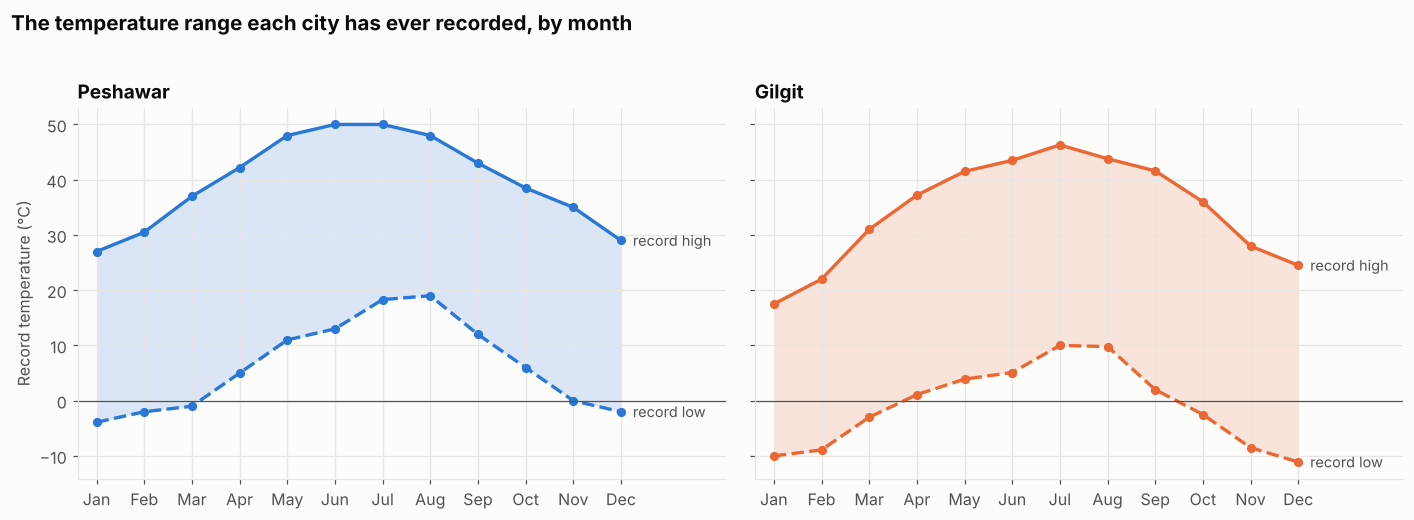

Hottest ever: Peshawar 50.0 °C (1995), Gilgit 46.3 °C (1997)
Coldest ever: Peshawar -3.9 °C, Gilgit -11.1 °C
Full record span (hottest minus coldest): {'Gilgit': 57.4, 'Peshawar': 53.9}


In [3]:
months = list(cl.month.cat.categories); x = np.arange(12)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (city, col) in zip(axes, [('Peshawar', BLUE), ('Gilgit', ORANGE)]):
    d = cl[cl.city==city].sort_values('month')
    ax.fill_between(x, d.record_min_c, d.record_max_c, color=col, alpha=.16, lw=0)
    ax.plot(x, d.record_max_c, color=col, lw=2.2, marker='o', ms=5); ax.plot(x, d.record_min_c, color=col, lw=2.2, marker='o', ms=5, ls='--')
    ax.axhline(0, color=MUTED, lw=.8)
    ax.text(11.25, d.record_max_c.iloc[-1], 'record high', va='center', color=MUTED, fontsize=9.5); ax.text(11.25, d.record_min_c.iloc[-1], 'record low', va='center', color=MUTED, fontsize=9.5)
    ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in months]); ax.set_xlim(-.4, 13.2); ax.set_title(city)
axes[0].set_ylabel('Record temperature (°C)'); fig.suptitle('The temperature range each city has ever recorded, by month', x=.01, ha='left', fontweight='bold', fontsize=13.5, y=1.02)
plt.tight_layout(); save('01_record_temperature_range.png')
hi = annual.set_index('city'); print(f"Hottest ever: Peshawar {hi.loc['Peshawar','record_max_c']} °C ({hi.loc['Peshawar','max_year']}), Gilgit {hi.loc['Gilgit','record_max_c']} °C ({hi.loc['Gilgit','max_year']})")
print(f"Coldest ever: Peshawar {hi.loc['Peshawar','record_min_c']} °C, Gilgit {hi.loc['Gilgit','record_min_c']} °C")
r = cl.groupby('city').apply(lambda g: g.record_max_c.max()-g.record_min_c.min()); print('Full record span (hottest minus coldest):', r.round(1).to_dict())

**Reading it:** Gilgit's band sits lower and is much wider in winter, with record lows near -11 °C, while Peshawar stays above freezing in most months. Both rise to a summer peak.

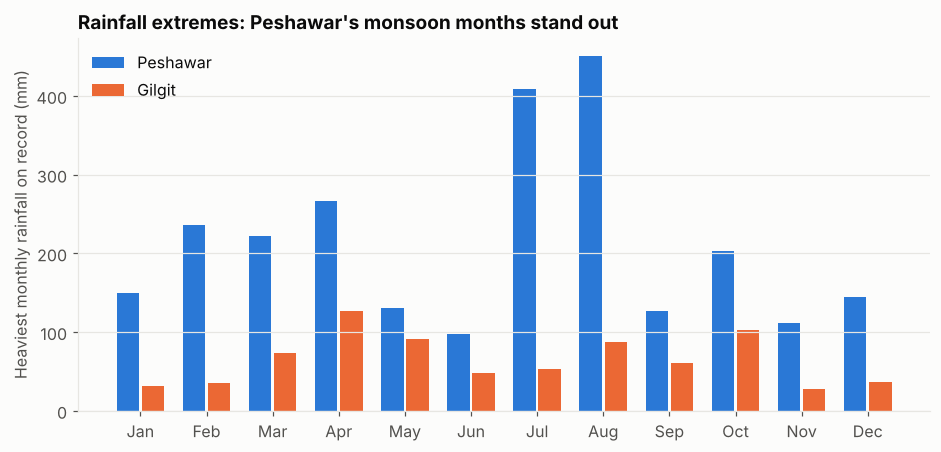

Month with the heaviest rainfall record: {'Gilgit': 'April', 'Peshawar': 'August'} | values (mm): {'Gilgit': 127.0, 'Peshawar': 451.0}


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.4)); w = .38
for k, (city, col) in enumerate([('Peshawar', BLUE), ('Gilgit', ORANGE)]):
    d = cl[cl.city==city].sort_values('month'); ax.bar(x + (k-.5)*w, d.record_rain_mm, w-.04, color=col, label=city)
ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in months]); ax.set_ylabel('Heaviest monthly rainfall on record (mm)'); ax.legend(loc='upper left')
ax.set_title('Rainfall extremes: Peshawar\'s monsoon months stand out'); ax.grid(axis='x', visible=False); save('02_record_rainfall.png')
piv = cl.pivot(index='month', columns='city', values='record_rain_mm'); print('Month with the heaviest rainfall record:', piv.idxmax().astype(str).to_dict(), '| values (mm):', piv.max().round(0).to_dict())

### When were the record highs set?
If warming were pushing records upward, recent decades should hold more of them. **Caveat:** each city has only 12 records, and the two records start in different years, so this is suggestive, not proof.

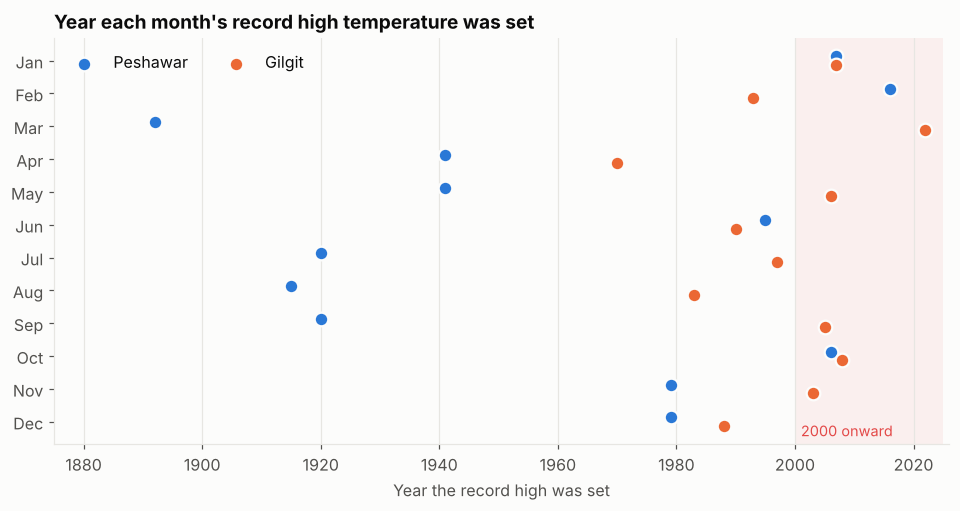

Record highs set in 2000 or later: {'Gilgit': '6 of 12', 'Peshawar': '3 of 12'}


In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.8)); ax.axvspan(2000, 2025, color=RED, alpha=.07, lw=0)
for city, col, dy in [('Peshawar', BLUE, -.13), ('Gilgit', ORANGE, .13)]:
    d = cl[cl.city==city]; ax.scatter(d.max_year, d.month.cat.codes + dy, s=80, color=col, edgecolor=SURF, linewidth=1.5, label=city, zorder=3)
ax.set_yticks(range(12)); ax.set_yticklabels([m[:3] for m in months]); ax.invert_yaxis(); ax.set_xlim(1875, 2026); ax.set_xlabel('Year the record high was set')
ax.text(2001, 11.55, '2000 onward', color=RED, fontsize=9.5, va='bottom'); ax.legend(loc='upper left', ncol=2); ax.grid(axis='y', visible=False)
ax.set_title('Year each month\'s record high temperature was set'); save('03_record_highs_timeline.png')
rec = cl.assign(recent=cl.max_year>=2000).groupby('city').recent.agg(['sum','size']); print('Record highs set in 2000 or later:', {c: f"{int(r['sum'])} of {int(r['size'])}" for c, r in rec.iterrows()})

## 2. Pakistan's temperature since 1870
`temp.csv` has yearly average temperatures for stations in many countries. Pakistan has up to 9 stations per year, which we average into one national value.

In [6]:
t = pd.read_csv('../data/temp.csv'); print('All countries:', t.shape, '| missing avg_temp:', f'{t.avg_temp.isna().mean():.1%}')
pk = t[t.country=='Pakistan'].dropna(subset=['avg_temp'])
pk_y = pk.groupby('year').agg(temp=('avg_temp','mean'), n_obs=('avg_temp','size')).reset_index()
print('Pakistan:', pk_y.year.min(), '-', pk_y.year.max(), '|', len(pk_y), 'years, up to', pk_y.n_obs.max(), 'stations per year')

All countries: (71311, 3) | missing avg_temp: 3.6%
Pakistan: 1796 - 2013 | 212 years, up to 9 stations per year


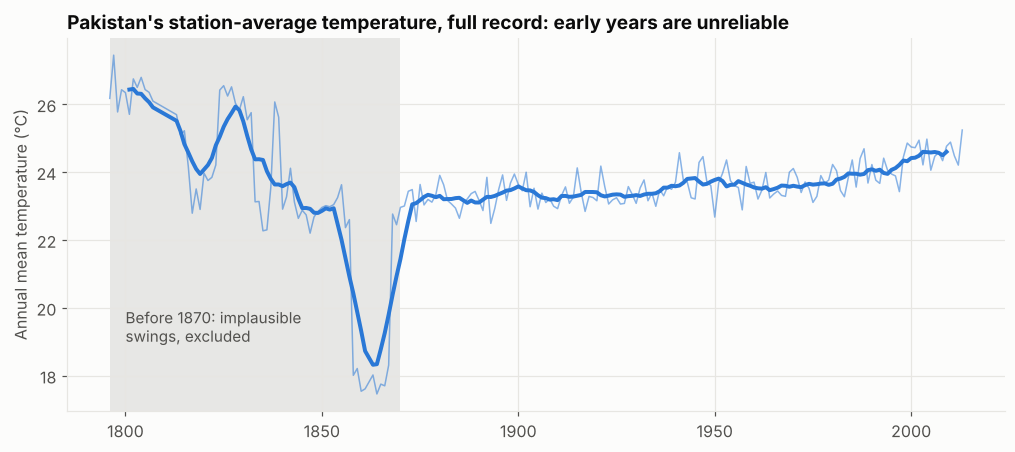

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(pk_y.year, pk_y.temp, color=BLUE, lw=1, alpha=.55); ax.plot(pk_y.year, pk_y.temp.rolling(10, center=True).mean(), color=BLUE, lw=2.6)
ax.axvspan(pk_y.year.min(), 1870, color=GREY, alpha=.3, lw=0); ax.text(1800, 19.0, 'Before 1870: implausible\nswings, excluded', color=MUTED, fontsize=10)
ax.set_ylabel('Annual mean temperature (°C)'); ax.set_title('Pakistan\'s station-average temperature, full record: early years are unreliable'); save('04_pakistan_temperature_full_record.png')

**Data-quality flag.** Before about 1870 the national mean swings between roughly 18 °C and 27 °C, including a drop of about 6 °C in the 1850s-60s. That is not a plausible climate signal for a whole country, and most likely reflects sparse or inconsistent early records. All trend tests therefore use **1870 onward**.

In [8]:
d = pk_y[pk_y.year>=1870].reset_index(drop=True); base = d[(d.year>=1900)&(d.year<=1929)].temp.mean(); d['anom'] = d.temp - base
print(f'Reference period 1900-1929 mean: {base:.2f} °C')
res = mk.original_test(d[d.year>=1900].temp.values); s1900 = res.slope*10
def pettitt(v):
    # Pettitt (1979) change-point test: returns (number of points before the shift, approximate p-value)
    v = np.asarray(v); n = len(v); U = np.array([np.sign(v[:k+1, None] - v[None, k+1:]).sum() for k in range(n-1)])
    K = np.abs(U).max(); return int(np.abs(U).argmax()) + 1, min(1.0, 2*np.exp(-6*K**2/(n**3 + n**2)))
cp_idx, cp_p = pettitt(d.temp.values); cp_year = int(d.year.iloc[cp_idx])
print(f'Mann-Kendall 1900-2013: {res.trend}, p = {res.p:.2g}, Sen slope = {res.slope:.4f} °C/yr = {s1900:.2f} °C per decade')
print(f'Pettitt change-point test (1870-2013): most likely shift around {cp_year}, p = {cp_p:.2g}')
print(f'Mean before / after {cp_year}: {d[d.year<cp_year].temp.mean():.2f} / {d[d.year>=cp_year].temp.mean():.2f} °C')

Reference period 1900-1929 mean: 23.32 °C


Mann-Kendall 1900-2013: increasing, p = 1.6e-13, Sen slope = 0.0109 °C/yr = 0.11 °C per decade
Pettitt change-point test (1870-2013): most likely shift around 1938, p = 5.6e-11
Mean before / after 1938: 23.30 / 23.92 °C


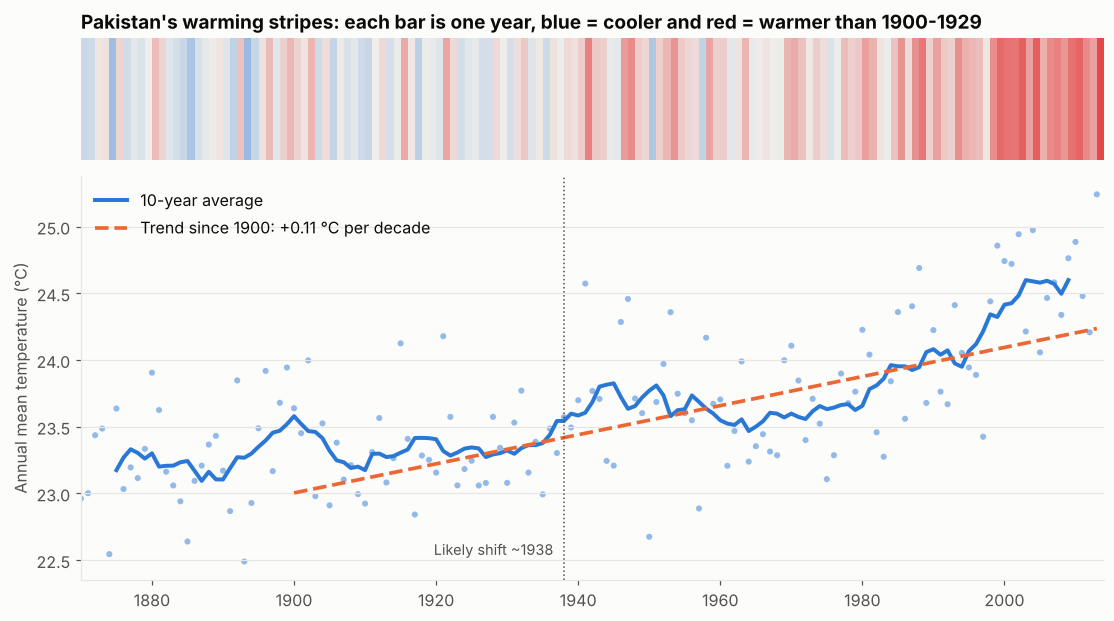

In [9]:
fig = plt.figure(figsize=(12, 6.4)); gs = GridSpec(2, 1, height_ratios=[1, 3.3], hspace=.06)
ax0 = fig.add_subplot(gs[0]); lim = np.abs(d.anom).max()
ax0.imshow(d.anom.values[None, :], aspect='auto', cmap=DIV, vmin=-lim, vmax=lim, extent=[d.year.min(), d.year.max()+1, 0, 1]); ax0.axis('off')
ax0.set_title('Pakistan\'s warming stripes: each bar is one year, blue = cooler and red = warmer than 1900-1929', loc='left', fontsize=12.5, fontweight='bold')
ax1 = fig.add_subplot(gs[1], sharex=ax0); ax1.set_xlim(d.year.min(), d.year.max()+1)
ax1.scatter(d.year, d.temp, s=16, color=BLUE, alpha=.5, edgecolor='none'); ax1.plot(d.year, d.temp.rolling(10, center=True).mean(), color=BLUE, lw=2.6, label='10-year average')
s = d[d.year>=1900]; ax1.plot(s.year, res.intercept + res.slope*(s.year - 1900), color=ORANGE, lw=2.4, ls='--', label=f'Trend since 1900: +{s1900:.2f} °C per decade')
ax1.axvline(cp_year, color=MUTED, lw=1, ls=':'); ax1.text(cp_year-1.5, d.temp.min()+.05, f'Likely shift ~{cp_year}', ha='right', color=MUTED, fontsize=9.5)
ax1.set_ylabel('Annual mean temperature (°C)'); ax1.legend(loc='upper left'); ax1.grid(axis='x', visible=False)
plt.savefig(FIG+'00_hero.png', dpi=170); plt.savefig(FIG+'05_warming_stripes_trend.png', dpi=160); plt.show()

### Trend strength depends on the period

,period,years,trend,p_value,sen_slope_C_per_decade
0,1870-2013,144,increasing,2.200000e-16,0.09
1,1900-2013,114,increasing,1.600000e-13,0.11
2,1950-2013,64,increasing,5.500000e-08,0.21
3,1980-2013,34,increasing,5.200000e-04,0.31


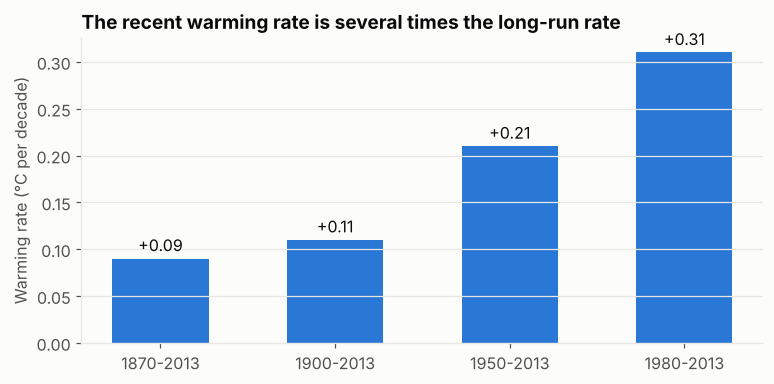

Decade mean: 23.32 °C in the 1900s to 24.70 °C in the 2010s (+1.38 °C)


In [10]:
rows = []
for a in [1870, 1900, 1950, 1980]:
    r_ = mk.original_test(d[d.year>=a].temp.values); rows.append(dict(period=f'{a}-2013', years=len(d[d.year>=a]), trend=r_.trend, p_value=float(f'{r_.p:.2g}'), sen_slope_C_per_decade=round(r_.slope*10, 2)))
mk_t = pd.DataFrame(rows); display(mk_t)
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(mk_t.period, mk_t.sen_slope_C_per_decade, color=BLUE, width=.55)
for i, v in enumerate(mk_t.sen_slope_C_per_decade): ax.text(i, v+.008, f'+{v:.2f}', ha='center', color=INK, fontsize=10.5)
ax.set_ylabel('Warming rate (°C per decade)'); ax.set_title('The recent warming rate is several times the long-run rate'); ax.grid(axis='x', visible=False); save('06_warming_rate_by_period.png')
dec = d.assign(decade=(d.year//10)*10).query('decade>=1900').groupby('decade').temp.mean(); print(f'Decade mean: {dec.iloc[0]:.2f} °C in the 1900s to {dec.iloc[-1]:.2f} °C in the 2010s (+{dec.iloc[-1]-dec.iloc[0]:.2f} °C)')

### Robustness: autocorrelation and confidence intervals
Yearly temperatures are correlated with their neighbours, which can make the plain Mann-Kendall test overconfident. We re-test with the Hamed-Rao autocorrelation correction and report 95% confidence intervals for the Theil-Sen slope.

,period,plain_p,adjusted_p,still_significant,slope_C_per_decade,ci95_low,ci95_high
0,1870-2013,2.200000e-16,2.500000e-08,True,0.09,0.07,0.10
1,1900-2013,1.600000e-13,1.000000e-06,True,0.11,0.08,0.14
2,1950-2013,5.500000e-08,5.500000e-08,True,0.21,0.15,0.26
3,1980-2013,5.200000e-04,5.200000e-04,True,0.31,0.16,0.45


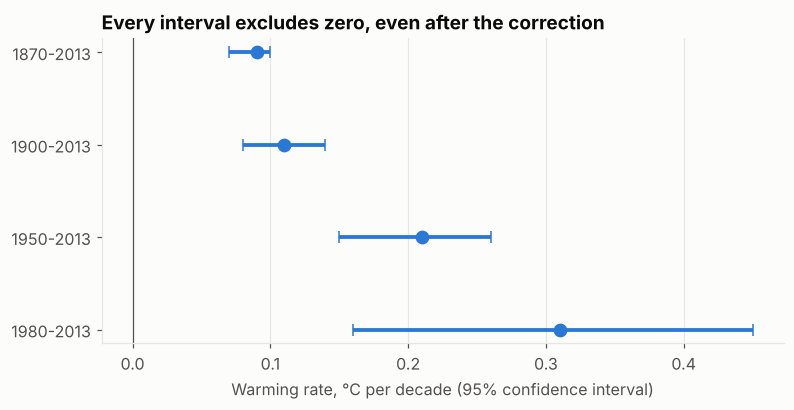

Lag-1 autocorrelation of annual temperature since 1870: 0.56


In [11]:
from scipy.stats import theilslopes
rows = []
for a in [1870, 1900, 1950, 1980]:
    s_ = d[d.year>=a]; plain = mk.original_test(s_.temp.values); hr = mk.hamed_rao_modification_test(s_.temp.values); sl, ic, lo, up = theilslopes(s_.temp.values, s_.year.values)
    rows.append(dict(period=f'{a}-2013', plain_p=float(f'{plain.p:.2g}'), adjusted_p=float(f'{hr.p:.2g}'), still_significant=bool(hr.p<.05), slope_C_per_decade=round(sl*10,2), ci95_low=round(lo*10,2), ci95_high=round(up*10,2)))
rb = pd.DataFrame(rows); display(rb)
fig, ax = plt.subplots(figsize=(8, 3.6)); yy = np.arange(len(rb))[::-1]
ax.errorbar(rb.slope_C_per_decade, yy, xerr=[rb.slope_C_per_decade-rb.ci95_low, rb.ci95_high-rb.slope_C_per_decade], fmt='o', color=BLUE, ecolor=BLUE, elinewidth=2.5, capsize=4, ms=8)
ax.set_yticks(yy); ax.set_yticklabels(rb.period); ax.axvline(0, color=MUTED, lw=.8); ax.set_xlabel('Warming rate, °C per decade (95% confidence interval)'); ax.grid(axis='y', visible=False)
ax.set_title('Every interval excludes zero, even after the correction' if (rb.ci95_low>0).all() else 'Not every interval excludes zero'); save('06b_warming_rate_confidence.png')
print('Lag-1 autocorrelation of annual temperature since 1870:', round(d.temp.autocorr(1), 2))

**Reading it:** the trend is significant in every period, and the rate grows when you look at recent decades. This says the temperature record is rising, not what caused it. The data is also not corrected for changes in stations or instruments.

## 3. Crop data: quality checks first
`yield_df.csv` combines FAO yield and pesticide data (1990-2013) with temperature and rainfall for 101 countries. Before using it we check it.

In [12]:
y = pd.read_csv('../data/yield_df.csv', index_col=0).rename(columns={'hg/ha_yield':'yield_hgha','average_rain_fall_mm_per_year':'rain_mm','pesticides_tonnes':'pesticides_t'})
const = (y.groupby('Area').rain_mm.nunique()==1).sum()
checks = pd.Series({'Rows': len(y), 'Missing values': int(y.isna().sum().sum()), 'Exact duplicate rows': int(y.duplicated().sum()),
    'Rows repeated on (country, crop, year)': int(y.duplicated(['Area','Item','Year']).sum()), 'Countries': y.Area.nunique(),
    f'Countries with ONE fixed rainfall value for all years': f'{const} of {y.Area.nunique()}'}); checks.to_frame('value')

,value
Rows,28242
Missing values,0
Exact duplicate rows,2310
"Rows repeated on (country, crop, year)",15112
Countries,101
Countries with ONE fixed rainfall value for all years,101 of 101


**What we found and what we did**
- The file has many repeated rows, because station temperatures were joined and copied across each crop-year. We keep one row per country-crop-year and average the temperature.
- **Rainfall is a single fixed number per country** (true for all 101 countries), so it cannot show year-to-year change. We do not use it to explain yield trends.

Clean data: (13130, 8) | countries: 101 | years 1990 - 2013


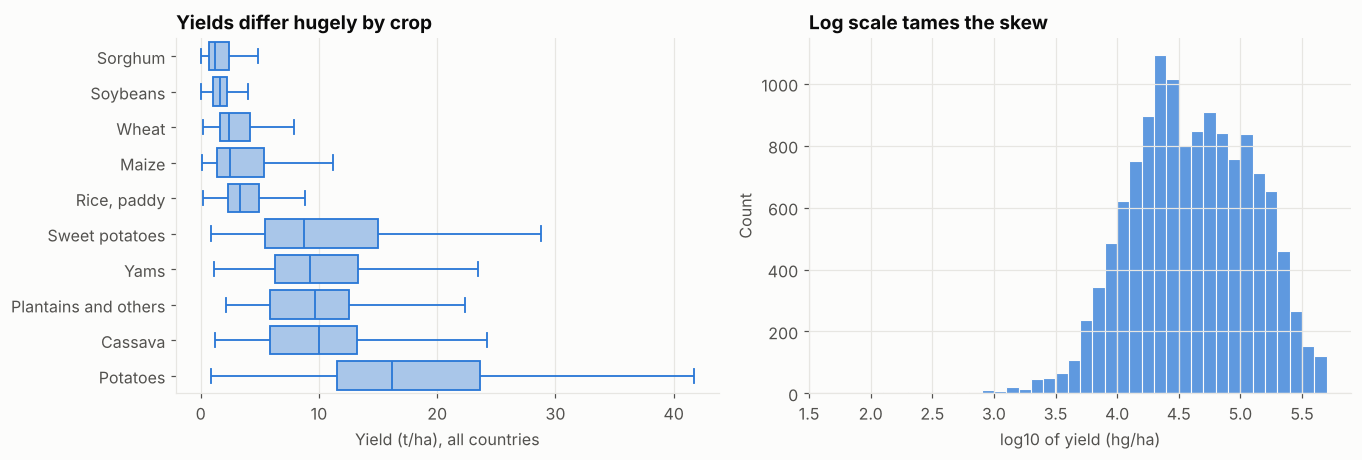

Skewness: raw 2.08 to -0.22 after log10


In [13]:
yc = (y.groupby(['Area','Item','Year'], as_index=False).agg(yield_hgha=('yield_hgha','first'), pesticides_t=('pesticides_t','first'), avg_temp=('avg_temp','mean'), rain_mm=('rain_mm','first')))
yc['yield_t_ha'] = yc.yield_hgha/10000   # hg/ha to t/ha
print('Clean data:', yc.shape, '| countries:', yc.Area.nunique(), '| years', yc.Year.min(), '-', yc.Year.max())
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
order = yc.groupby('Item').yield_t_ha.median().sort_values().index
sns.boxplot(data=yc, y='Item', x='yield_t_ha', order=order, ax=ax[0], showfliers=False, color='#9ec5f4', linecolor=BLUE, linewidth=1.2); ax[0].set_xlabel('Yield (t/ha), all countries'); ax[0].set_ylabel(''); ax[0].set_title('Yields differ hugely by crop')
sns.histplot(np.log10(yc.yield_hgha), bins=40, ax=ax[1], color=BLUE, edgecolor=SURF); ax[1].set_xlabel('log10 of yield (hg/ha)'); ax[1].set_title('Log scale tames the skew')
plt.tight_layout(); save('07_yield_distribution.png'); print(f'Skewness: raw {yc.yield_hgha.skew():.2f} to {np.log10(yc.yield_hgha).skew():.2f} after log10')

## 4. Pakistan's crops, 1990-2013

In [14]:
p = yc[yc.Area=='Pakistan'].sort_values(['Item','Year']).copy()
from scipy.stats import theilslopes
res = []
for it, g in p.groupby('Item'):
    r_ = mk.original_test(g.yield_t_ha.values); hr_ = mk.hamed_rao_modification_test(g.yield_t_ha.values); sl, ic, lo, up = theilslopes(g.yield_t_ha.values, g.Year.values)
    res.append(dict(crop=it, mean_yield_t_ha=round(g.yield_t_ha.mean(),2), trend=r_.trend, p_value=float(f'{r_.p:.2g}'), adjusted_p=float(f'{hr_.p:.2g}'), slope_t_ha_per_yr=round(sl,3), ci95_low=round(lo,3), ci95_high=round(up,3), pct_per_yr=round(100*sl/g.yield_t_ha.mean(),1), intercept=ic, slope_raw=sl))
pk_mk = pd.DataFrame(res).sort_values('pct_per_yr', ascending=False).reset_index(drop=True); display(pk_mk.drop(columns=['intercept','slope_raw']))

,crop,mean_yield_t_ha,trend,p_value,adjusted_p,slope_t_ha_per_yr,ci95_low,ci95_high,pct_per_yr
0,Maize,2.44,increasing,1.700000e-09,7.100000e-06,0.134,0.111,0.154,5.5
1,Potatoes,15.93,increasing,6.900000e-07,6.900000e-07,0.500,0.412,0.561,3.1
2,"Rice, paddy",3.01,increasing,2.200000e-08,2.200000e-08,0.056,0.046,0.067,1.9
3,Wheat,2.32,increasing,3.900000e-08,3.900000e-08,0.042,0.036,0.050,1.8
4,Sweet potatoes,10.48,no trend,1.500000e-01,3.000000e-01,0.058,-0.014,0.095,0.6
5,Sorghum,0.61,increasing,2.200000e-04,2.200000e-04,0.002,0.001,0.002,0.3
6,Soybeans,0.93,no trend,9.600000e-01,9.700000e-01,-0.001,-0.033,0.016,-0.1


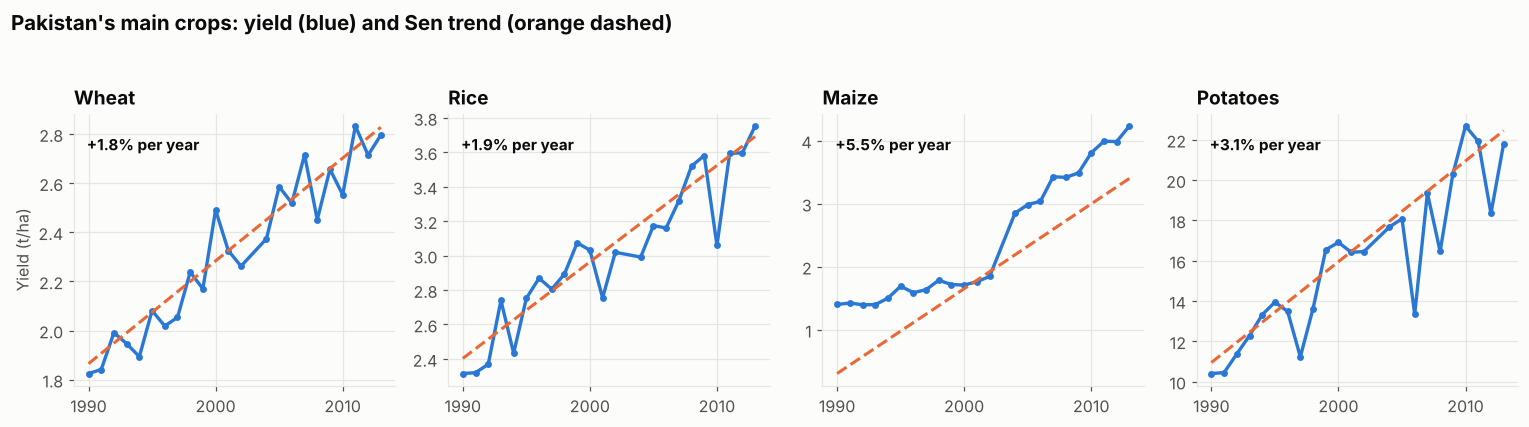

Significant increase (autocorrelation-adjusted): ['Maize', 'Potatoes', 'Rice, paddy', 'Wheat', 'Sorghum'] | no significant trend: ['Sweet potatoes', 'Soybeans']


In [15]:
key = ['Wheat','Rice, paddy','Maize','Potatoes']; fig, axes = plt.subplots(1, 4, figsize=(14, 3.7))
for ax, it in zip(axes, key):
    g = p[p.Item==it]; m = pk_mk.set_index('crop').loc[it]; ax.plot(g.Year, g.yield_t_ha, color=BLUE, lw=2.2, marker='o', ms=3.5)
    ax.plot(g.Year, m.intercept + m.slope_raw*g.Year, color=ORANGE, lw=2, ls='--')
    ax.set_title(it.replace(', paddy','')); ax.set_xticks([1990, 2000, 2010]); ax.text(.04, .92, f'{m.pct_per_yr:+.1f}% per year', transform=ax.transAxes, color=INK, fontsize=10, va='top', fontweight='bold')
axes[0].set_ylabel('Yield (t/ha)'); fig.suptitle('Pakistan\'s main crops: yield (blue) and Sen trend (orange dashed)', x=.01, ha='left', fontweight='bold', fontsize=13.5, y=1.04)
plt.tight_layout(); save('08_pakistan_crop_trends.png')
sig = pk_mk[pk_mk.adjusted_p<.05].crop.tolist(); non = pk_mk[pk_mk.adjusted_p>=.05].crop.tolist(); print('Significant increase (autocorrelation-adjusted):', sig, '| no significant trend:', non)

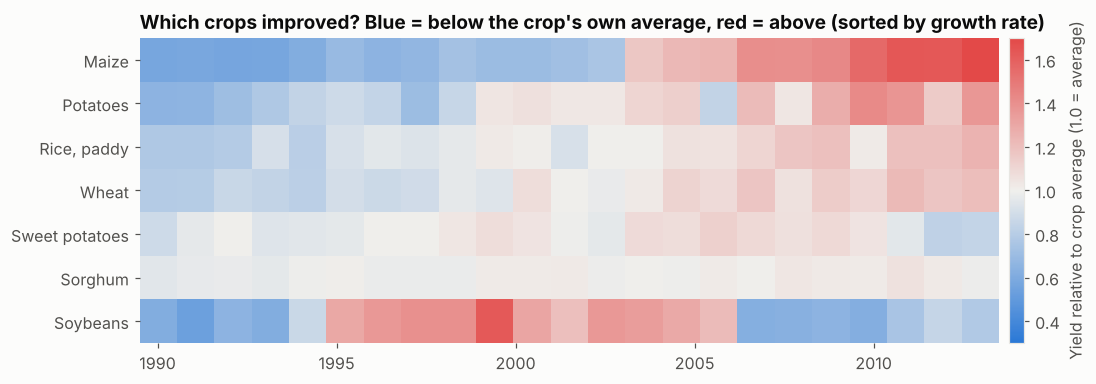

In [16]:
piv = p.pivot(index='Item', columns='Year', values='yield_t_ha'); idx = piv.div(piv.mean(axis=1), axis=0).loc[pk_mk.crop]
fig, ax = plt.subplots(figsize=(12, 3.6)); im = ax.imshow(idx.values, aspect='auto', cmap=DIV, norm=TwoSlopeNorm(vmin=.3, vcenter=1, vmax=1.7), extent=[1989.5, 2013.5, len(idx), 0])
ax.set_yticks(np.arange(len(idx))+.5); ax.set_yticklabels(idx.index); ax.grid(False); ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=.01); cb.set_label('Yield relative to crop average (1.0 = average)'); ax.set_title('Which crops improved? Blue = below the crop\'s own average, red = above (sorted by growth rate)'); save('09_pakistan_yield_heatmap.png')

**A caution on maize:** its yield was flat near 1.5 t/ha until about 2002, then jumped to above 4 t/ha by 2013. A straight trend line therefore fits it poorly, and the +5.8% per year figure averages over a flat period and a steep one. The data cannot tell us why (new varieties, area changes or reporting changes are all possible).

### How does Pakistan compare?
Pakistan against other countries on **wheat**, its staple. India is its neighbour with a similar growing environment, and Egypt is another irrigated, arid-climate producer.

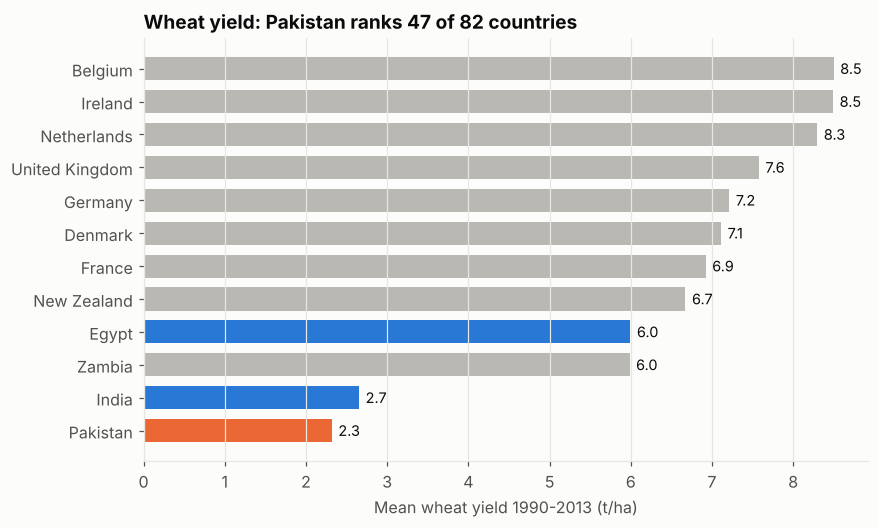

Top-10 average wheat yield is 3.1x Pakistan's (7.3 vs 2.3 t/ha)


In [17]:
wh = yc[yc.Item=='Wheat'].groupby('Area').yield_t_ha.mean().sort_values(ascending=False); n = len(wh); rank = int(wh.index.get_loc('Pakistan'))+1
show = pd.concat([wh.head(10), wh[['India','Egypt','Pakistan']]]).loc[lambda s: ~s.index.duplicated()].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5)); cols = [ORANGE if a=='Pakistan' else (BLUE if a in ('India','Egypt') else GREY) for a in show.index]
ax.barh(show.index, show.values, color=cols, height=.7); ax.grid(axis='y', visible=False)
for i, v in enumerate(show.values): ax.text(v+.08, i, f'{v:.1f}', va='center', fontsize=9.5, color=INK)
ax.set_xlabel('Mean wheat yield 1990-2013 (t/ha)'); ax.set_title(f'Wheat yield: Pakistan ranks {rank} of {n} countries'); save('10_wheat_ranking.png')
gap = wh.head(10).mean()/wh['Pakistan']; print(f'Top-10 average wheat yield is {gap:.1f}x Pakistan\'s ({wh.head(10).mean():.1f} vs {wh["Pakistan"]:.1f} t/ha)')

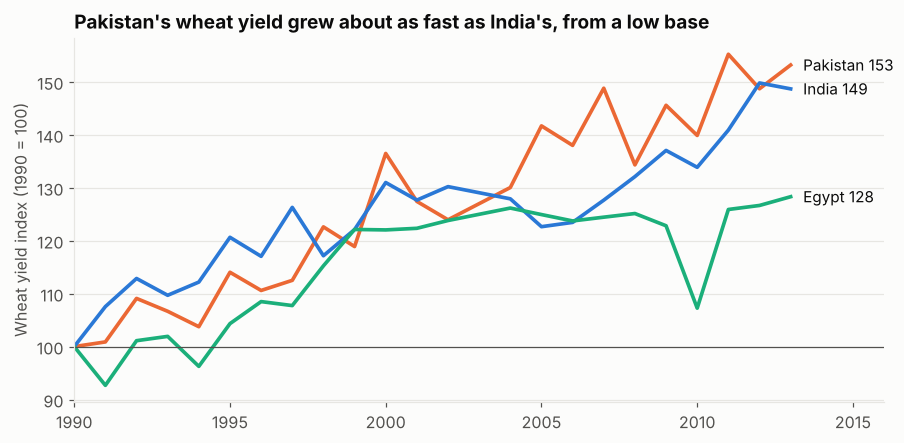

In [18]:
cmp = [c for c in ['Pakistan','India','Egypt'] if c in yc[yc.Item=='Wheat'].Area.unique()]; cols = {'Pakistan':ORANGE,'India':BLUE,'Egypt':AQUA}
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for c in cmp:
    g = yc[(yc.Area==c)&(yc.Item=='Wheat')].sort_values('Year'); idx_ = 100*g.yield_t_ha/g.yield_t_ha.iloc[0]; ax.plot(g.Year, idx_, color=cols[c], lw=2.4)
    ax.text(g.Year.max()+.4, idx_.iloc[-1], f'{c} {idx_.iloc[-1]:.0f}', color=INK, va='center', fontsize=10)
ax.axhline(100, color=MUTED, lw=.8); ax.set_xlim(1990, 2016); ax.set_ylabel('Wheat yield index (1990 = 100)'); ax.set_title('Pakistan\'s wheat yield grew about as fast as India\'s, from a low base'); ax.grid(axis='x', visible=False); save('11_wheat_growth_index.png')

### Does temperature explain yield changes?
Both yields and temperature rise over time, so a raw correlation looks strong **even if the two are unrelated**. A fairer check correlates *year-to-year changes*.

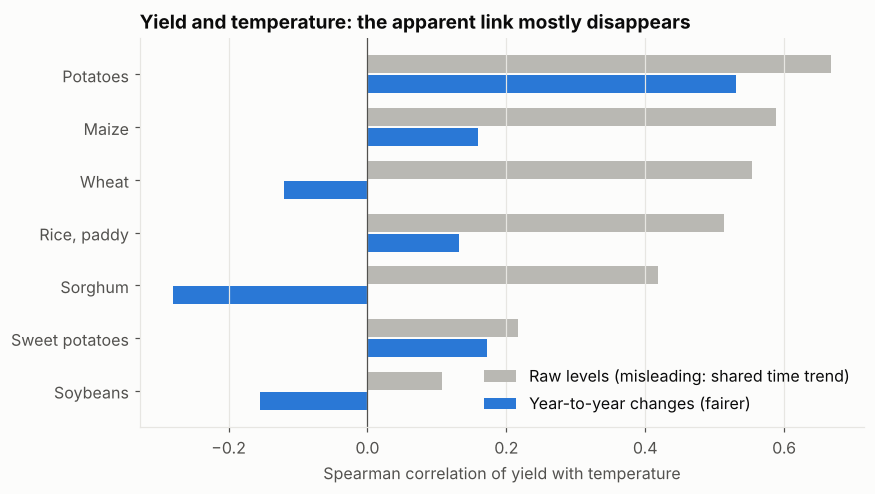

Raw range: 0.11 to 0.67 | year-to-year change range: -0.28 to 0.53 | n = 23 years per crop


In [19]:
raw = p.groupby('Item').apply(lambda g: g.yield_t_ha.corr(g.avg_temp, method='spearman'))
dif = p.groupby('Item').apply(lambda g: g.yield_t_ha.diff().corr(g.avg_temp.diff(), method='spearman'))
cc = pd.DataFrame({'raw':raw, 'change':dif}).sort_values('raw'); yy = np.arange(len(cc)); fig, ax = plt.subplots(figsize=(8.5, 4.6)); h = .38
ax.barh(yy+h/2, cc.raw, h-.04, color=GREY, label='Raw levels (misleading: shared time trend)'); ax.barh(yy-h/2, cc['change'], h-.04, color=BLUE, label='Year-to-year changes (fairer)')
ax.set_yticks(yy); ax.set_yticklabels(cc.index); ax.axvline(0, color=MUTED, lw=.8); ax.set_xlabel('Spearman correlation of yield with temperature'); ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
ax.set_title('Yield and temperature: the apparent link mostly disappears'); save('12_yield_temperature_correlation.png')
print('Raw range:', f'{cc.raw.min():.2f} to {cc.raw.max():.2f}', '| year-to-year change range:', f'{cc["change"].min():.2f} to {cc["change"].max():.2f}', '| n = 23 years per crop')

## 5. Conclusions and limitations
**What the data supports**
- Pakistan's station-average temperature rose significantly since 1870, and the rate is higher in recent decades. A change-point test places the largest single step in the mean at about 1938 (23.3 to 23.9 °C), yet the series keeps warming, and faster after 1980, so one step does not describe it fully.
- Gilgit's record highs are more recent than Peshawar's, which fits warming but rests on only 12 values per city.
- Most of Pakistan's crop yields rose from 1990 to 2013, led by maize and potatoes. Pakistan's wheat yield grew about as fast as India's (both about +50% since 1990) but remains well below the top producers.
- There is no clear evidence in this data that temperature drives yield changes.

**Limits to keep in mind**
- Peshawar and Gilgit are record tables, not yearly series, so no trend tests were possible for them.
- The temperature series is not corrected for station or instrument changes, and the pre-1870 record is unreliable.
- Rainfall in the crop file is constant per country and was not used.
- Crop data has only 23-24 years, which limits statistical power. Correlation and trend tests do not establish causes.

**Next steps:** add real yearly rainfall for Pakistan, add basin-level hydrology data, and test detrended or lagged yield-climate models.